# Lahares secundarios del Volcán de Fuego a partir de lluvia GPM/IMERG

En este notebook se hace **todo el experimento de la tesis**, paso por paso, desde la descarga de la lluvia hasta guardar los modelos. La idea es que cualquier persona lo pueda correr y llegue a los mismos resultados.

| Paso | Qué se hace | Apartado de la tesis |
|---|---|---|
| 1 | Leer la lluvia de NASA Giovanni y revisar que esté completa | 3.2, 3.3 |
| 2 | Revisar la tabla de lahares, que es la etiqueta | 3.4 |
| 3 | Calcular las 13 variables de lluvia | 3.5 |
| 4 | Armar el conjunto de datos y aplicar los filtros | 3.6, 4.1, 4.2 |
| 5 | Partir por años y entrenar los tres modelos | 3.7, 3.8, 4.3 |
| 6 | Evaluar con la prueba y elegir el modelo | 3.9, 4.3 |
| 7 | Importancia de variables, umbral y errores | 4.4, 4.5 |
| 8 | Evaluación con los datos de 2026 (IMERG Late) | 4.6 |
| 9 | Satélite contra el pluviómetro del volcán | 3.3.1 |
| 10 | Guardar los modelos, la ecuación y los datos de la librería | 5 |
| 11 | Usar la librería para predecir, entrenar y ajustar | 5 |

**Cómo correrlo:** primero se instala lo de `requirements.txt` y la librería con `pip install -e .`, y luego en Jupyter se usa *Run → Run All Cells*. Tarda unos minutos, el paso 5 es el que más se tarda.
Las tablas y figuras quedan en la carpeta `resultados/` y los modelos en `modelos/`.

Los resultados de la tesis se obtuvieron con Python 3.10.7 y las versiones de `requirements.txt`. Si se usa otra versión de scikit-learn, el bosque aleatorio puede elegir otros hiperparámetros y dar métricas un poco distintas.

## Configuración
Aquí está todo lo que se puede cambiar, como las rutas de los archivos, los años de entrenamiento y prueba, y la sensibilidad que se busca.

In [1]:
import io, json, platform, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import sys
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
# la librería del repositorio (pip install -e .), o directo desde src/
try:                                     
    import lahares_fuego as lf
except ImportError:
    sys.path.insert(0, "src"); import lahares_fuego as lf
from lahares_fuego import VARIABLES, calcular_variables, leer_lluvia, metricas, umbral_por_sensibilidad
from lahares_fuego.modelo import GRILLAS, construir

DATOS = Path("data")
IMERG_FINAL = DATOS / "raw/imerg/giovanni_GPM_3IMERGDF_07_fuego_20180101-20250930.csv"
IMERG_LATE = DATOS / "raw/imerg/giovanni_GPM_3IMERGDL_07_fuego_20180101-20261015.csv"
TABLA_DIARIA = DATOS / "procesado/tabla_diaria_lahares_fuego.csv"
PLUVIOMETRO = DATOS / "procesado/pluviometro_fuego_bvd.csv"
RESULTADOS, MODELOS = Path("resultados"), Path("modelos")
# aquí se guardan los datos y modelos que trae la librería
PAQUETE = Path("src/lahares_fuego/datos")        
for d in (RESULTADOS / "figuras", RESULTADOS / "tablas", MODELOS, PAQUETE):
    d.mkdir(parents=True, exist_ok=True)

 # Es la unión de todas las fuentes (Esta en el apartado 3.6 del tesis)
ETIQUETA = "ocurrencia_union"           
ANIOS_ENTRENAMIENTO = [2019, 2020, 2021, 2022, 2023]
ANIOS_PRUEBA = [2024, 2025]
# último día de IMERG Final al momento de la descarga
FIN_FINAL = "2025-09-30"
# evaluación con IMERG Late
OPERATIVO = ("2025-10-01", "2026-09-19") 
SENSIBILIDAD_OBJETIVO = 0.80
SEMILLA = 42
NOMBRES = {"regresion_logistica": "Regresión logística", "bosque_aleatorio": "Bosque aleatorio", "svm_rbf": "SVM (kernel RBF)"}
COLORES = {"regresion_logistica": "#2E6F9E", "bosque_aleatorio": "#D9822B", "svm_rbf": "#3A9A5B"}
MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
pd.set_option("display.width", 160)

def guardar_figura(fig, nombre):
    fig.savefig(RESULTADOS / "figuras" / nombre, dpi=200, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | joblib {joblib.__version__}")

Python 3.10.7 | scikit-learn 1.7.2 | pandas 2.3.3 | numpy 2.2.6 | matplotlib 3.10.9 | joblib 1.6.0


## Lluvia de NASA Giovanni (En los apartados 3.2 y 3.3 del tesis)

Los dos CSV se descargaron de Giovanni con el servicio *Time Series, Area-Averaged*, en la caja −90.95, 14.40, −90.80, 14.55. Giovanni ajusta esa caja a la malla del producto, por lo que al final queda una sola celda de 0.1° que contiene la cumbre.
- **Final** (GPM_3IMERGDF.07): es la que está calibrada con pluviómetros, y es la que se usa para entrenar y probar.
- **Late** (GPM_3IMERGDL.07): está disponible unas 14 horas después de la lluvia, y se usa solo para la evaluación de 2026.

Aquí se revisan tres cosas, que no falte ningún día, que no haya valores de relleno (−9999.9) y que los máximos sean posibles para la zona.

In [2]:
final = leer_lluvia(IMERG_FINAL)
late = leer_lluvia(IMERG_LATE)
for nombre, s in (("Final", final), ("Late", late)):
    print(f"IMERG {nombre}: {s.fecha_utc.min().date()} a {s.fecha_utc.max().date()}, {len(s)} días, "
          f"sin dato: {int(s.lluvia_mm.isna().sum())}, máximo: {s.lluvia_mm.max():.1f} mm "
          f"({s.loc[s.lluvia_mm.idxmax(), 'fecha_utc'].date()})")

IMERG Final: 2018-01-01 a 2025-09-30, 2830 días, sin dato: 0, máximo: 84.4 mm (2022-11-28)
IMERG Late: 2018-01-01 a 2026-10-15, 3210 días, sin dato: 0, máximo: 157.8 mm (2026-10-04)


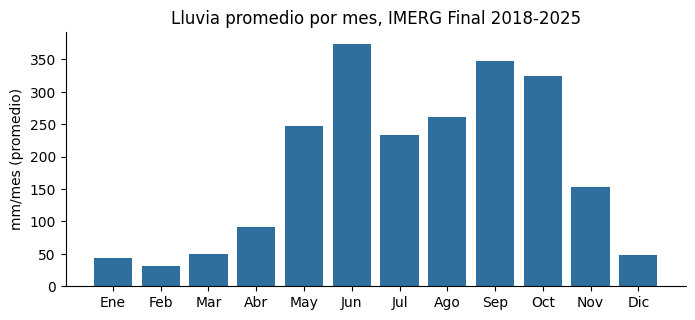

In [3]:
m = final.groupby(final.fecha_utc.dt.month).lluvia_mm.mean() * 30.4
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(MESES, m.values, color="#2E6F9E"); ax.set(ylabel="mm/mes (promedio)", title="Lluvia promedio por mes, IMERG Final 2018-2025")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
guardar_figura(fig, "01_lluvia_mensual.png")

Se ve que la época de lluvias va de mayo a octubre, con una baja en julio y agosto, que es la canícula.

## La tabla de lahares (En el apartado 3.4 de la tesis)

El archivo `tabla_diaria_lahares_fuego.csv` tiene una fila por cada día local, del 1 de enero de 2019 al 19 de septiembre de 2026, y una columna por cada fuente: GVP, CONRED (con la fecha movida un día atrás), los boletines BEFGO publicados, las publicaciones en X, el catálogo sísmico de Bejar Lopez et al. (2025) y el archivo de boletines que entregó el INSIVUMEH por la solicitud UIP-546-2026.
La etiqueta que se usa es `ocurrencia_union`, la cual vale 1 si cualquiera de las fuentes registra un lahar ese día.

También tiene la columna `confiabilidad_negativo`, que dice qué tan seguro es que un día sin lahar de verdad no tuvo lahar, y `dia_eruptivo_excluir`, que marca los días en que el lahar aparece en un boletín de erupción.

In [4]:
t = pd.read_csv(TABLA_DIARIA, encoding="utf-8-sig", parse_dates=["fecha"], keep_default_na=False)
fuentes = {"ocurrencia_gvp": "GVP", "ocurrencia_conred_ajust": "CONRED", "ocurrencia_insivumeh": "BEFGO publicados",
           "ocurrencia_x": "X", "ocurrencia_recomendada": "Documental", "ocurrencia_sismica": "Sísmico",
           "ocurrencia_insivumeh_laip": "Archivo INSIVUMEH", "ocurrencia_union": "Unión"}
p = t[t.fecha <= FIN_FINAL]
tabla5 = (p[list(fuentes)].apply(pd.to_numeric, errors="coerce").fillna(0) > 0).groupby(p.anio).sum().rename(columns=fuentes)
tabla5.loc["Total"] = tabla5.sum()
tabla5.to_csv(RESULTADOS / "tablas/tabla5_lahares_por_fuente.csv", encoding="utf-8-sig")
tabla5

,GVP,CONRED,BEFGO publicados,X,Documental,Sísmico,Archivo INSIVUMEH,Unión
anio,,,,,,,,
2019,21,25,0,0,35,42,7,57
2020,20,7,0,7,28,39,41,55
2021,17,1,0,8,20,44,27,51
2022,26,1,0,0,27,73,43,82
2023,52,1,0,4,52,0,56,56
2024,7,6,1,3,17,0,40,43
2025,13,2,7,3,21,0,47,48
Total,156,43,8,25,200,198,261,392


Un mismo día puede aparecer en varias fuentes, por eso las columnas no se suman. Aquí se ve por qué no alcanza con una sola fuente, ya que el catálogo sísmico (2019 a 2022) registra casi el doble de días que las fuentes documentales, y desde 2023 la que más aporta es el archivo del INSIVUMEH.

In [5]:
pd.crosstab(t.anio, t.confiabilidad_negativo)

confiabilidad_negativo,alta,baja,media
anio,,,
2019,365,0,0
2020,366,0,0
2021,365,0,0
2022,365,0,0
2023,365,0,0
2024,91,163,112
2025,0,204,161
2026,0,150,112


Todos los días de confiabilidad **baja**, es decir, los que no tienen boletín del GVP, están de 2024 en adelante. En esos días un cero no demuestra que no hubo lahar, por lo que esos días sin lahar no se usan.

## Variables de lluvia (En el apartado 3.5 de la tesis)

Las variables se calculan con la función `calcular_variables` de la librería `lahares_fuego`, la cual es la misma que usa cualquier persona que quiera aplicar el modelo, así siempre se calculan igual. Son 13 variables por día:
`lluvia_mm`, `lluvia_ayer`, los acumulados de 2, 3, 5, 7, 14 y 30 días, `max_diaria_7d`, `dias_secos_previos`, `api_k09` (el índice de precipitación antecedente, con k = 0.9) y `mes_sin` y `mes_cos` para la estacionalidad.

**Para no usar lluvia del futuro:** el día UTC D va de las 18:00 hora local del día D−1 a las 18:00 del día D. Por eso, para el lahar del día local D solo se usa la lluvia hasta el día UTC D. En la tabla de abajo se ve con un ejemplo.

In [6]:
pd.DataFrame({"momento (hora local)": ["17-sep 15:00", "17-sep 17:59", "17-sep 18:00", "17-sep 23:00"],
              "momento (UTC)": ["17-sep 21:00", "17-sep 23:59", "18-sep 00:00", "18-sep 05:00"],
              "lluvia cuenta para el día UTC": ["17-sep", "17-sep", "18-sep", "18-sep"]})

,momento (hora local),momento (UTC),lluvia cuenta para el día UTC
0,17-sep 15:00,17-sep 21:00,17-sep
1,17-sep 17:59,17-sep 23:59,17-sep
2,17-sep 18:00,18-sep 00:00,18-sep
3,17-sep 23:00,18-sep 05:00,18-sep


## Conjunto de datos (En los apartados 3.6, 4.1 y 4.2 de la tesis)

Aquí se une la etiqueta del día local D con las variables del día UTC D, y después se aplican tres filtros:
1. Se quitan los días eruptivos, ya que el lahar pudo ser primario.
2. Se quitan los días sin lahar que tienen confiabilidad baja.
3. Se quitan los días que todavía no tienen historia para el acumulado de 30 días.

In [7]:
def armar(lluvia, desde, hasta):
    X = calcular_variables(lluvia)
    df = t.merge(X, left_on="fecha", right_on="fecha_utc", how="inner")
    df = df[(df.fecha >= desde) & (df.fecha <= hasta)].copy()
    df["y"] = df[ETIQUETA].astype(int)
    f = {"días unidos": len(df)}
    erup = df.dia_eruptivo_excluir.astype(int) == 1
    f["quitados: eruptivos"] = int(erup.sum()); df = df[~erup]
    baja = (df.y == 0) & (df.confiabilidad_negativo == "baja")
    f["quitados: confiabilidad baja"] = int(baja.sum()); df = df[~baja]
    n = len(df); df = df.dropna(subset=VARIABLES)
    f["quitados: sin historia"] = n - len(df); f["días finales"] = len(df)
    df = df[["fecha", "anio", "y"] + VARIABLES].reset_index(drop=True)
    df = pd.read_csv(io.StringIO(df.to_csv(index=False)), parse_dates=["fecha"])
    return df, f

datos, f1 = armar(final, "2019-01-01", FIN_FINAL)
operativo, f2 = armar(late, *OPERATIVO)
pd.DataFrame({"principal (Final)": f1, "operativo (Late)": f2})

,principal (Final),operativo (Late)
días unidos,2465,354
quitados: eruptivos,6,0
quitados: confiabilidad baja,258,198
quitados: sin historia,0,0
días finales,2201,156


In [8]:
anual = pd.concat([datos.assign(conjunto="principal"), operativo.assign(conjunto="operativo")]) \
          .groupby(["conjunto", "anio"]).y.agg(dias="size", con_lahar="sum")
anual["% con lahar"] = (100 * anual.con_lahar / anual.dias).round(1)
anual.to_csv(RESULTADOS / "tablas/conjunto_por_anio.csv", encoding="utf-8-sig")
anual

dias  con_lahar  % con lahar
conjunto  anio                              
operativo 2025    35          9         25.7
          2026   121         23         19.0
principal 2019   365         57         15.6
          2020   366         55         15.0
          2021   364         51         14.0
          2022   363         82         22.6
          2023   364         56         15.4
          2024   224         43         19.2
          2025   155         46         29.7

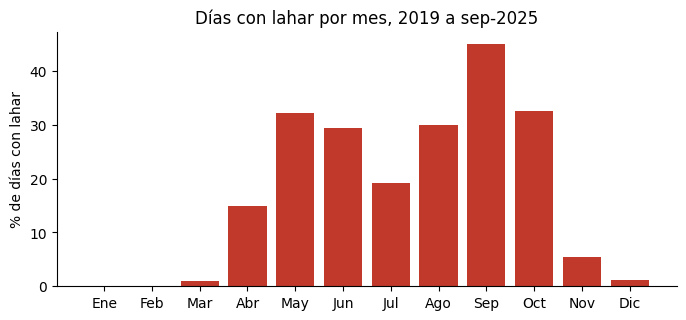

In [9]:
meses = datos.groupby(datos.fecha.dt.month).y.mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.bar(MESES, meses.values, color="#C0392B"); ax.set(ylabel="% de días con lahar", title="Días con lahar por mes, 2019 a sep-2025")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
guardar_figura(fig, "04_lahares_por_mes.png")

**Lluvia en los días con y sin lahar** (mediana en mm). La diferencia más grande está en la lluvia del mismo día, y se va haciendo más pequeña entre más larga es la ventana.

In [10]:
cols = ["lluvia_mm", "acum_3d", "acum_7d", "acum_30d", "max_diaria_7d", "api_k09"]
clase = datos.groupby("y")[cols].median().T.round(1)
clase.columns = ["sin lahar", "con lahar"]
clase["veces mayor"] = (clase["con lahar"] / clase["sin lahar"]).round(1)
clase.to_csv(RESULTADOS / "tablas/lluvia_por_clase.csv", encoding="utf-8-sig")
clase

,sin lahar,con lahar,veces mayor
lluvia_mm,1.1,11.2,10.2
acum_3d,6.4,31.8,5.0
acum_7d,22.2,71.7,3.2
acum_30d,124.7,273.6,2.2
max_diaria_7d,9.4,22.9,2.4
api_k09,39.6,93.5,2.4


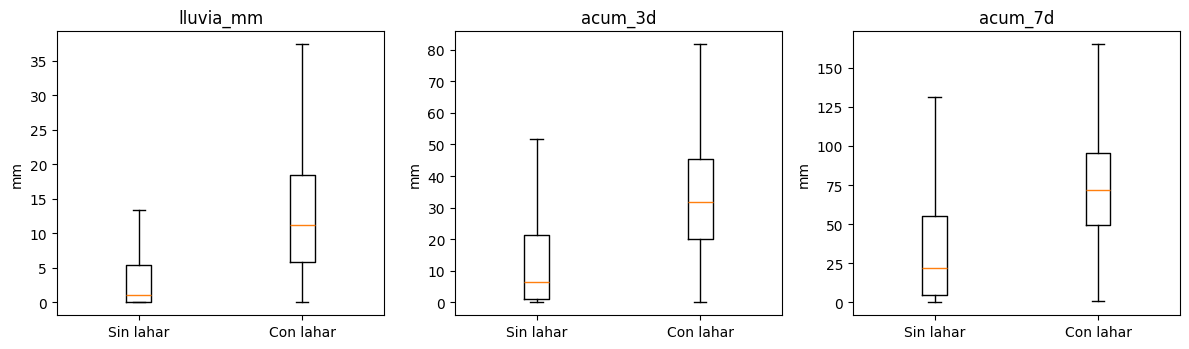

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, c in zip(axs, ["lluvia_mm", "acum_3d", "acum_7d"]):
    ax.boxplot([datos.loc[datos.y == 0, c], datos.loc[datos.y == 1, c]], showfliers=False)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Sin lahar", "Con lahar"]); ax.set(title=c, ylabel="mm")
fig.tight_layout(); guardar_figura(fig, "04_lluvia_por_clase.png")

In [12]:
c = datos[VARIABLES].corr().abs()
pares = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().dropna().sort_values(ascending=False)
print(f"Pares con correlación mayor a 0.8: {(pares > 0.8).sum()} de {len(pares)}")
pares.head(5).round(2)

Pares con correlación mayor a 0.8: 16 de 78


acum_14d  api_k09    0.97
acum_30d  api_k09    0.94
acum_5d   acum_7d    0.94
acum_2d   acum_3d    0.91
acum_7d   api_k09    0.90
dtype: float64

## La partición y entrenamiento (En los apartados 3.7 y 3.8 de la tesis)

- **Entrenamiento:** de 2019 a 2023. **Prueba:** de enero de 2024 a septiembre de 2025. La partición se hace por años y no al azar, para que el modelo se entrene con el pasado y se pruebe con años que no conoce.
- Los hiperparámetros se buscan con validación cruzada temporal de 5 pliegues (`TimeSeriesSplit`), escogiendo la mayor PR-AUC.
- El desbalance de clases se trata con `class_weight="balanced"`.
- **Umbral:** se elige con las predicciones de la validación cruzada, como el valor más alto que todavía detecta por lo menos el 80 % de los lahares. Se define antes de ver la prueba.

In [13]:
ent = datos[datos.anio.isin(ANIOS_ENTRENAMIENTO)]
pru = datos[datos.anio.isin(ANIOS_PRUEBA)]
print(f"Entrenamiento: {len(ent)} días, {ent.y.sum()} con lahar | Prueba: {len(pru)} días, {pru.y.sum()} con lahar")
print(f"Exactitud de un modelo que siempre dice 'no hay lahar' en la prueba: {1 - pru.y.mean():.1%}")

# Los tres modelos y sus grillas vienen de la librería (lahares_fuego/modelo.py), así el paquete y la tesis usan lo mismo
MODELOS_Y_GRILLAS = {n: (construir(n, SEMILLA), GRILLAS[n]) for n in ["regresion_logistica", "bosque_aleatorio", "svm_rbf"]}
GRILLAS

Entrenamiento: 1822 días, 301 con lahar | Prueba: 379 días, 89 con lahar
Exactitud de un modelo que siempre dice 'no hay lahar' en la prueba: 76.5%


{'regresion_logistica': {'logisticregression__C': [0.01, 0.1, 1, 10]},
 'bosque_aleatorio': {'n_estimators': [300],
  'max_depth': [3, 5, 8, None],
  'min_samples_leaf': [1, 5, 20]},
 'svm_rbf': {'svc__C': [0.1, 1, 10], 'svc__gamma': ['scale', 0.01, 0.1]}}

In [14]:
X, y = ent[VARIABLES], ent.y.values
cv = TimeSeriesSplit(n_splits=5)
E = {}
for nombre, (modelo, grilla) in MODELOS_Y_GRILLAS.items():
    gs = GridSearchCV(modelo, grilla, scoring="average_precision", cv=cv, n_jobs=-1).fit(X, y)
    idx, p_oof = [], []
    for tr, te in cv.split(X):                                   # predicciones fuera de pliegue
        m = clone(gs.best_estimator_).fit(X.iloc[tr], y[tr])
        idx.extend(te); p_oof.extend(m.predict_proba(X.iloc[te])[:, 1])
    idx, p_oof = np.array(idx), np.array(p_oof)
    E[nombre] = dict(modelo=clone(gs.best_estimator_).fit(X, y), parametros=gs.best_params_, pr_auc_cv=gs.best_score_,
                     y_oof=y[idx], p_oof=p_oof, umbral=umbral_por_sensibilidad(y[idx], p_oof, SENSIBILIDAD_OBJETIVO))

pd.DataFrame({NOMBRES[n]: {"hiperparámetros": e["parametros"], "PR-AUC validación cruzada": round(e["pr_auc_cv"], 3),
                           "umbral": round(e["umbral"], 3)} for n, e in E.items()}).T

,hiperparámetros,PR-AUC validación cruzada,umbral
Regresión logística,{'logisticregression__C': 0.1},0.463,0.484
Bosque aleatorio,"{'max_depth': 8, 'min_samples_leaf': 20, 'n_es...",0.46,0.468
SVM (kernel RBF),"{'svc__C': 1, 'svc__gamma': 0.01}",0.463,0.154


## Evaluación con la prueba y elección del modelo (En los apartados 3.9 y 4.3 de la tesis)

La métrica principal es la PR-AUC, cuyo valor de azar es la proporción de días con lahar. También se calcula la ROC-AUC y, ya con el umbral, la sensibilidad, la especificidad, la precisión, el F2 y la matriz de confusión.

In [15]:
probs = {}
filas = []
for n, e in E.items():
    filas.append({"modelo": n, "conjunto": "validación cruzada", **metricas(e["y_oof"], e["p_oof"], e["umbral"])})
    for conj, df in (("prueba", pru), ("operativa 2026", operativo)):
        probs[(n, conj)] = e["modelo"].predict_proba(df[VARIABLES])[:, 1]
        filas.append({"modelo": n, "conjunto": conj, **metricas(df.y.values, probs[(n, conj)], e["umbral"])})
tabla = pd.DataFrame(filas)
tabla.to_csv(RESULTADOS / "tablas/metricas_modelos.csv", index=False, encoding="utf-8-sig")
tabla[tabla.conjunto != "operativa 2026"].set_index(["modelo", "conjunto"])

n  con_lahar   azar  pr_auc  roc_auc  umbral  sensibilidad  especificidad  precision     f2   VP   FP  FN   VN
modelo              conjunto                                                                                                                             
regresion_logistica validación cruzada  1515        245  0.162   0.444    0.841   0.484         0.800          0.741      0.373  0.651  196  329  49  941
                    prueba               379         89  0.235   0.508    0.819   0.484         0.843          0.662      0.434  0.709   75   98  14  192
bosque_aleatorio    validación cruzada  1515        245  0.162   0.449    0.845   0.468         0.800          0.743      0.375  0.652  196  326  49  944
                    prueba               379         89  0.235   0.529    0.833   0.468         0.820          0.734      0.487  0.721   73   77  16  213
svm_rbf             validación cruzada  1515        245  0.162   0.435    0.844   0.154         0.800          0.750      0.381  0.656  196  318  49  952
                    prueba               379         89  0.235   0.490    0.823   0.154         0.865          0.676      0.450  0.731   77   94  12  196

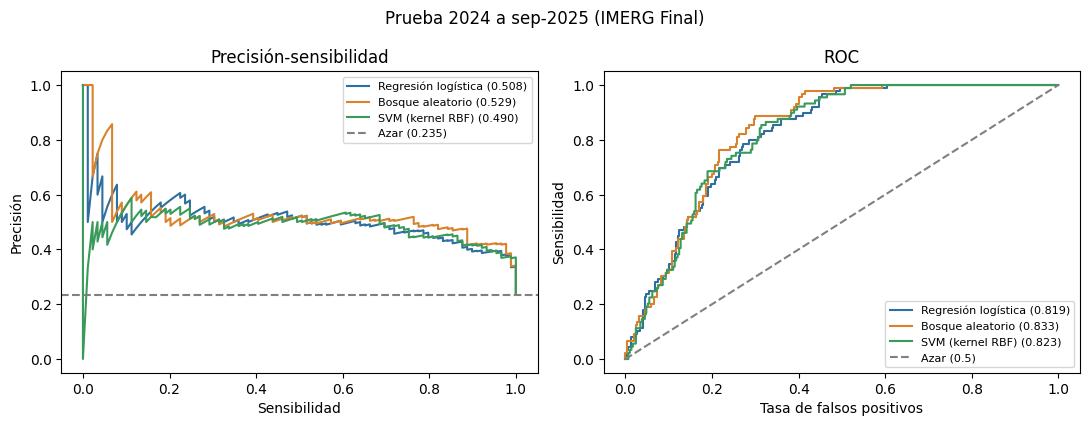

In [16]:
def curvas(y, ps, titulo, archivo):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
    for n, p in ps.items():
        pr, rc, _ = precision_recall_curve(y, p); fpr, tpr, _ = roc_curve(y, p)
        ax[0].plot(rc, pr, color=COLORES[n], label=f"{NOMBRES[n]} ({average_precision_score(y, p):.3f})")
        ax[1].plot(fpr, tpr, color=COLORES[n], label=f"{NOMBRES[n]} ({roc_auc_score(y, p):.3f})")
    ax[0].axhline(np.mean(y), ls="--", c="gray", label=f"Azar ({np.mean(y):.3f})"); ax[1].plot([0, 1], [0, 1], ls="--", c="gray", label="Azar (0.5)")
    ax[0].set(xlabel="Sensibilidad", ylabel="Precisión", title="Precisión-sensibilidad"); ax[1].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad", title="ROC")
    for a in ax: a.legend(fontsize=8)
    fig.suptitle(titulo); fig.tight_layout(); guardar_figura(fig, archivo)

curvas(pru.y.values, {n: probs[(n, "prueba")] for n in E}, "Prueba 2024 a sep-2025 (IMERG Final)", "06_curvas_prueba.png")

**Cómo se elige el modelo (en el apartado 3.9 de la tesis):** primero el de mayor PR-AUC en la prueba; si la diferencia entre dos es menor de 0.02, el de mayor sensibilidad; y si siguen empatados, el más simple, en el orden regresión logística, bosque aleatorio y SVM.

In [17]:
prueba = tabla[tabla.conjunto == "prueba"].set_index("modelo")
orden = ["regresion_logistica", "bosque_aleatorio", "svm_rbf"]
cand = prueba[prueba.pr_auc >= prueba.pr_auc.max() - 0.02]
if len(cand) > 1:
    cand = cand[cand.sensibilidad == cand.sensibilidad.max()]
ELEGIDO = sorted(cand.index, key=orden.index)[0]
pr_ord = prueba.pr_auc.sort_values(ascending=False)
print(f"Modelo elegido: {NOMBRES[ELEGIDO]} | diferencia con el segundo: {pr_ord.iloc[0] - pr_ord.iloc[1]:.3f}")

Modelo elegido: Bosque aleatorio | diferencia con el segundo: 0.021


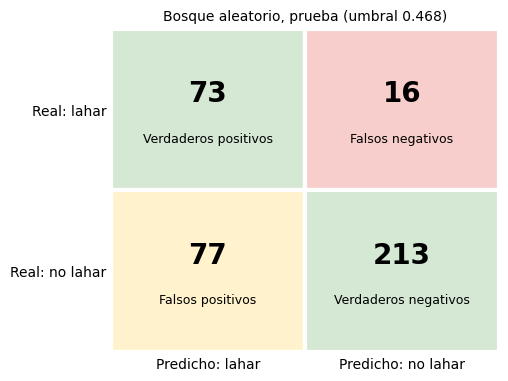

In [18]:
def matriz(y, p, umbral, titulo, archivo):
    r = metricas(y, p, umbral)
    m = np.array([[r["VP"], r["FN"]], [r["FP"], r["VN"]]])
    etiquetas = [["Verdaderos positivos", "Falsos negativos"], ["Falsos positivos", "Verdaderos negativos"]]
    colores = [["#D5E8D4", "#F8CECC"], ["#FFF2CC", "#D5E8D4"]]
    fig, ax = plt.subplots(figsize=(5, 4.2))
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=colores[i][j], ec="white", lw=3))
            ax.text(j + .5, 1 - i + .55, str(m[i, j]), ha="center", fontsize=20, weight="bold")
            ax.text(j + .5, 1 - i + .3, etiquetas[i][j], ha="center", fontsize=9)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2)
    ax.set_xticks([.5, 1.5]); ax.set_xticklabels(["Predicho: lahar", "Predicho: no lahar"])
    ax.set_yticks([1.5, .5]); ax.set_yticklabels(["Real: lahar", "Real: no lahar"])
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_title(f"{titulo} (umbral {umbral:.3f})", fontsize=10); guardar_figura(fig, archivo)

e = E[ELEGIDO]
matriz(pru.y.values, probs[(ELEGIDO, "prueba")], e["umbral"], f"{NOMBRES[ELEGIDO]}, prueba", "06_matriz_prueba.png")

## Importancia de variables, umbral y errores (En los apartados 4.4 y 4.5 de la tesis)

**Importancia por permutación:** mide cuánto baja la PR-AUC de la prueba cuando se desordenan los valores de una variable. Hay que tomar en cuenta que las ventanas de lluvia están correlacionadas, por lo que la importancia se reparte entre variables parecidas y es mejor leerla por grupos.

,permutacion,desviacion,impureza
lluvia_mm,0.0666,0.0245,0.2506
acum_2d,0.0289,0.0282,0.1650
acum_5d,0.0145,0.0206,0.1056
acum_14d,0.0128,0.0194,0.0568
mes_cos,0.0125,0.0183,0.0452
max_diaria_7d,0.0118,0.0165,0.0679
acum_7d,0.0097,0.0191,0.0812
acum_3d,0.0090,0.0213,0.1185
lluvia_ayer,0.0082,0.0150,0.0317
acum_30d,0.0057,0.0118,0.0333


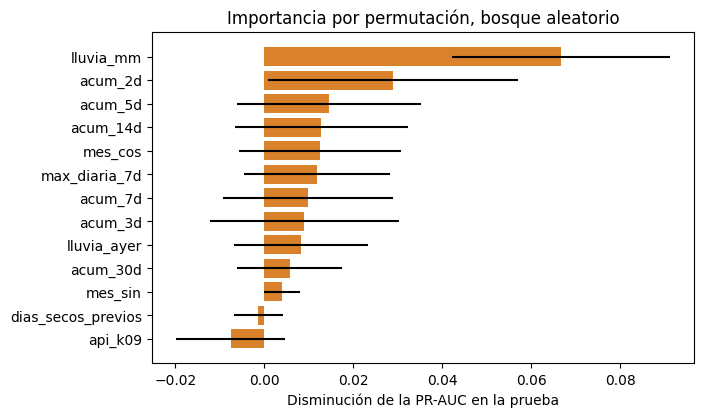

In [19]:
pi = permutation_importance(e["modelo"], pru[VARIABLES], pru.y, scoring="average_precision", n_repeats=30, random_state=SEMILLA)
imp = pd.DataFrame({"permutacion": pi.importances_mean, "desviacion": pi.importances_std}, index=VARIABLES)
if hasattr(e["modelo"], "feature_importances_"):
    imp["impureza"] = e["modelo"].feature_importances_
imp = imp.sort_values("permutacion", ascending=False).round(4)
imp.to_csv(RESULTADOS / "tablas/importancia_variables.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7, 4.3))
s = imp.permutacion.sort_values()
ax.barh(s.index, s.values, xerr=imp.desviacion.reindex(s.index), color="#D9822B")
ax.set(xlabel="Disminución de la PR-AUC en la prueba", title=f"Importancia por permutación, {NOMBRES[ELEGIDO].lower()}")
guardar_figura(fig, "07_importancia.png")
imp

**Otros umbrales:** si se baja el umbral se detectan más lahares, pero a cambio salen más falsas alarmas.

In [20]:
p = probs[(ELEGIDO, "prueba")]
umbrales = sorted(set(np.round(np.arange(0.2, 0.71, 0.1), 2)) | {round(e["umbral"], 3)})
alt = pd.DataFrame([metricas(pru.y.values, p, u) for u in umbrales]).set_index("umbral")[["sensibilidad", "especificidad", "precision", "VP", "FP", "FN"]]
alt.to_csv(RESULTADOS / "tablas/umbrales_alternativos.csv", encoding="utf-8-sig")
alt

,sensibilidad,especificidad,precision,VP,FP,FN
umbral,,,,,,
0.200,0.955,0.600,0.423,85,116,4
0.300,0.888,0.662,0.446,79,98,10
0.400,0.854,0.707,0.472,76,85,13
0.468,0.820,0.734,0.487,73,77,16
0.500,0.798,0.741,0.486,71,75,18
0.600,0.719,0.786,0.508,64,62,25
0.700,0.517,0.845,0.505,46,45,43


**Lahares que no se detectaron** en la prueba. Si la mayoría tiene muy poca lluvia estimada ese día, quiere decir que el error viene de que el satélite no captó la tormenta, y no del modelo.

In [21]:
d = pru[["fecha", "y", "lluvia_mm", "acum_3d", "acum_7d"]].assign(probabilidad=p.round(3), alerta=(p >= e["umbral"]).astype(int))
no_detectados = d[(d.y == 1) & (d.alerta == 0)]
no_detectados.to_csv(RESULTADOS / "tablas/lahares_no_detectados.csv", index=False, encoding="utf-8-sig")
fp = d[(d.y == 0) & (d.alerta == 1)]
cerca = sum(((d.y == 1) & ((d.fecha - f).abs().dt.days <= 1)).any() for f in fp.fecha)
print(f"No detectados: {len(no_detectados)} (lluvia mediana {no_detectados.lluvia_mm.median():.1f} mm) | "
      f"falsas alarmas: {len(fp)}, de las cuales {cerca} están a un día o menos de un lahar registrado")
no_detectados

No detectados: 16 (lluvia mediana 2.8 mm) | falsas alarmas: 77, de las cuales 38 están a un día o menos de un lahar registrado


,fecha,y,lluvia_mm,acum_3d,acum_7d,probabilidad,alerta
1917,2024-04-07,1,0.000,6.121,6.250,0.197,0
1918,2024-04-08,1,1.307,3.851,7.557,0.098,0
1920,2024-04-27,1,0.359,1.064,9.562,0.039,0
1928,2024-05-10,1,1.050,24.239,26.160,0.183,0
1929,2024-05-11,1,2.448,4.429,28.513,0.205,0
1931,2024-05-15,1,3.053,66.609,71.096,0.425,0
1983,2024-08-20,1,3.040,36.244,56.274,0.366,0
1997,2024-09-23,1,2.600,11.560,60.612,0.410,0
2016,2024-10-31,1,3.813,9.137,14.095,0.227,0
2024,2024-11-08,1,3.103,20.404,68.255,0.368,0


**Comparación con referencias simples:** aquí se ordenan los días solo por una variable de lluvia, sin ningún modelo, para ver cuánto aporta realmente el modelo.

In [22]:
refs = []
for conj, g, pm in (("prueba", pru, probs[(ELEGIDO, "prueba")]), ("operativa 2026", operativo, probs[(ELEGIDO, "operativa 2026")])):
    refs.append({"conjunto": conj, "referencia": "azar", "pr_auc": g.y.mean(), "roc_auc": 0.5})
    for col in ["lluvia_mm", "acum_3d", "acum_7d"]:
        refs.append({"conjunto": conj, "referencia": f"solo {col}", "pr_auc": average_precision_score(g.y, g[col]), "roc_auc": roc_auc_score(g.y, g[col])})
    refs.append({"conjunto": conj, "referencia": NOMBRES[ELEGIDO], "pr_auc": average_precision_score(g.y, pm), "roc_auc": roc_auc_score(g.y, pm)})
refs = pd.DataFrame(refs).round(3).set_index(["conjunto", "referencia"])
refs.to_csv(RESULTADOS / "tablas/referencias_simples.csv", encoding="utf-8-sig")
refs

pr_auc  roc_auc
conjunto       referencia                       
prueba         azar               0.235    0.500
               solo lluvia_mm     0.542    0.838
               solo acum_3d       0.537    0.818
               solo acum_7d       0.477    0.792
               Bosque aleatorio   0.529    0.833
operativa 2026 azar               0.205    0.500
               solo lluvia_mm     0.704    0.897
               solo acum_3d       0.611    0.859
               solo acum_7d       0.707    0.885
               Bosque aleatorio   0.762    0.903

## Evaluación con los datos de 2026 (En el apartado 4.6)

Se usan los mismos modelos y umbrales, sin volver a entrenar nada, con la lluvia del **"IMERG Late"** de octubre de 2025 a septiembre de 2026. Es decir, con la lluvia que se tendría en la práctica pocas horas después de que llueve.

In [23]:
tabla[tabla.conjunto == "operativa 2026"].set_index("modelo")

,conjunto,n,con_lahar,azar,pr_auc,roc_auc,umbral,sensibilidad,especificidad,precision,f2,VP,FP,FN,VN
modelo,,,,,,,,,,,,,,,
regresion_logistica,operativa 2026,156,32,0.205,0.724,0.885,0.484,0.750,0.782,0.471,0.67,24,27,8,97
bosque_aleatorio,operativa 2026,156,32,0.205,0.762,0.903,0.468,0.750,0.823,0.522,0.69,24,22,8,102
svm_rbf,operativa 2026,156,32,0.205,0.727,0.897,0.154,0.781,0.815,0.521,0.71,25,23,7,101


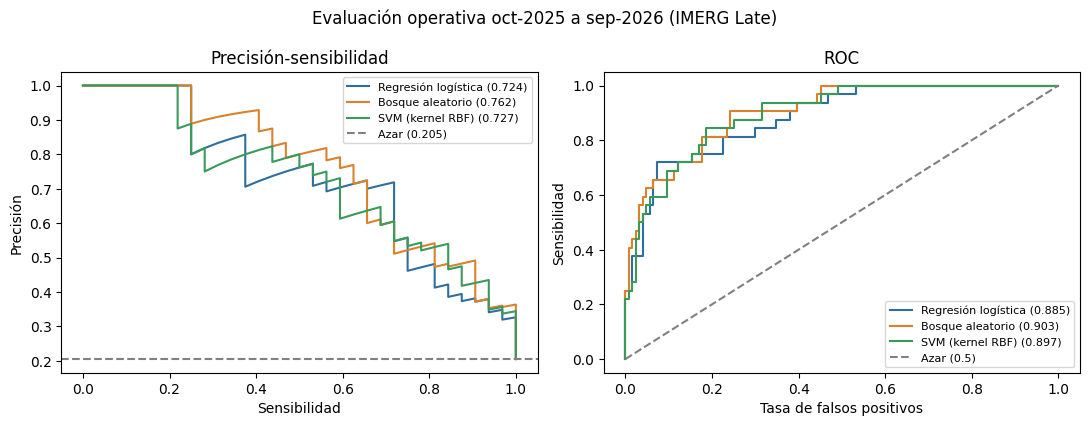

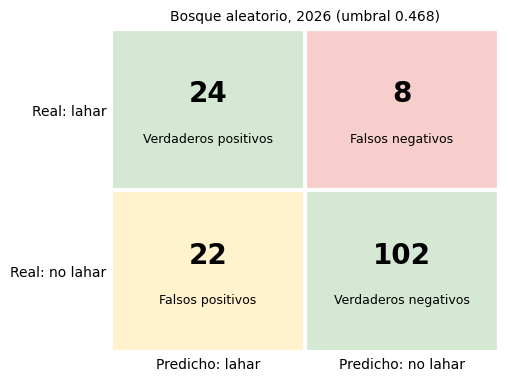

In [24]:
curvas(operativo.y.values, {n: probs[(n, "operativa 2026")] for n in E}, "Evaluación operativa oct-2025 a sep-2026 (IMERG Late)", "08_curvas_operativa.png")
matriz(operativo.y.values, probs[(ELEGIDO, "operativa 2026")], e["umbral"], f"{NOMBRES[ELEGIDO]}, 2026", "08_matriz_operativa.png")

## Satélite contra el pluviómetro del volcán (En el apartado 3.3.1 de la tesis)

La lluvia de la estación del Volcán de Fuego sale de los boletines diarios del INSIVUMEH. El boletín del día D trae la lluvia del día anterior, por eso la columna `fecha_lluvia` es D − 1.

In [25]:
pl = pd.read_csv(PLUVIOMETRO, parse_dates=["fecha_lluvia"])
pl = pl[pl.revisar == 0].drop_duplicates("fecha_lluvia").set_index("fecha_lluvia").lluvia_mm
f = final.set_index("fecha_utc").lluvia_mm
l = late.set_index("fecha_utc").lluvia_mm

def comparar(ref, ev, nombre):
    m = pd.concat([ref, ev], axis=1, sort=True).dropna(); x, y = m.iloc[:, 0], m.iloc[:, 1]
    return {"comparación": nombre, "días": len(m), "media referencia (mm)": round(x.mean(), 2), "media satélite (mm)": round(y.mean(), 2),
            "sesgo (%)": round(100 * (y.sum() - x.sum()) / x.sum(), 1), "Pearson": round(x.corr(y), 3),
            "Spearman": round(x.corr(y, method="spearman"), 3)}

comp = pd.DataFrame([comparar(f["2019":], l["2019":FIN_FINAL], "Final vs Late 2019-2025"),
                     comparar(pl["2019":FIN_FINAL], f["2019":], "Pluviómetro vs Final 2019-2025"),
                     comparar(pl["2026":], l["2026":], "Pluviómetro vs Late 2026")]).set_index("comparación")
comp.to_csv(RESULTADOS / "tablas/satelite_vs_pluviometro.csv", encoding="utf-8-sig")
comp.T

comparación,Final vs Late 2019-2025,Pluviómetro vs Final 2019-2025,Pluviómetro vs Late 2026
días,2465.000,2058.000,125.000
media referencia (mm),6.060,13.700,14.000
media satélite (mm),6.120,5.940,6.550
sesgo (%),0.900,-56.600,-53.200
Pearson,0.944,0.413,0.420
Spearman,0.959,0.609,0.506


El satélite registra cerca de la mitad de la lluvia que mide el pluviómetro. Como el modelo aprende y se aplica con la misma serie del satélite, esto no impide la clasificación, pero sí quiere decir que los valores de lluvia del modelo no se pueden usar como umbrales para un pluviómetro.

## Guardar los modelos, la ecuación y los datos de la librería (En el capítulo 5 de la tesis)

Aquí se guardan tres cosas:

1. **Los tres modelos entrenados** en `modelos/*.joblib`, cada uno con su umbral. Para abrirlos se necesita scikit-learn, de preferencia la misma versión.
2. **La ecuación de la regresión logística** en `modelos/ECUACION.md`, la cual se puede usar en Excel o en cualquier lenguaje sin instalar nada:

$$p = \frac{1}{1 + e^{-z}}, \qquad z = b_0 + \sum_{i=1}^{13} w_i \, x_i$$

   El modelo se entrenó con las variables estandarizadas, $z = \beta_0 + \sum \beta_i (x_i - \mu_i)/\sigma_i$, y al despejar queda $w_i = \beta_i/\sigma_i$ y $b_0 = \beta_0 - \sum \beta_i \mu_i/\sigma_i$, por lo que los coeficientes ya quedan en milímetros o días.
3. **Los datos de la librería** `lahares_fuego` en `src/lahares_fuego/datos/`, que son el conjunto de datos de la tesis y un resumen con los hiperparámetros, umbrales, métricas y la ecuación. Con esto `lf.cargar_modelo()` puede armar los mismos modelos en cualquier computadora.

El bosque aleatorio (300 árboles) y la SVM no tienen una ecuación que se pueda escribir, por eso se usan con el archivo .joblib o con la librería.

In [26]:
versiones = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__}
for n, ee in E.items():
    m = lf.ModeloLahares(n, hiperparametros=ee["parametros"])
    m.estimador, m.umbral = ee["modelo"], ee["umbral"]
    m.info = {"entrenado_con": "2019-01-01 a 2023-12-31", "hiperparametros": ee["parametros"], "versiones": versiones}
    m.guardar(MODELOS / f"{n}.joblib")
m_rl = lf.ModeloLahares("regresion_logistica"); m_rl.estimador, m_rl.umbral = E["regresion_logistica"]["modelo"], E["regresion_logistica"]["umbral"]
ec = m_rl.ecuacion()

# datos y resumen que trae la librería
conjunto = pd.concat([ent.assign(conjunto="entrenamiento"), pru.assign(conjunto="prueba"), operativo.assign(conjunto="operativo")])
conjunto[["fecha", "conjunto", "y"] + VARIABLES].to_csv(PAQUETE / "conjunto_tesis.csv", index=False, encoding="utf-8", float_format="%.17g")
resumen = {"descripcion": "Modelos de la tesis: lahares secundarios del Volcán de Fuego con IMERG diario (celda -90.95, 14.45, -90.85, 14.55)",
           "versiones": versiones, "modelo_elegido": ELEGIDO, "ecuacion_regresion_logistica": {k: ec[k] for k in ("intercepto", "coeficientes", "formula")},
           "modelos": {n: {"hiperparametros": ee["parametros"], "umbral": ee["umbral"],
                           "prueba": metricas(pru.y.values, probs[(n, "prueba")], ee["umbral"]),
                           "operativa_2026": metricas(operativo.y.values, probs[(n, "operativa 2026")], ee["umbral"])} for n, ee in E.items()}}
(PAQUETE / "modelos_tesis.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

pd.Series(ec["coeficientes"], name="w (por unidad de la variable)").round(6)

lluvia_mm             0.057914
acum_2d               0.016179
acum_3d              -0.002080
acum_5d               0.006463
acum_7d               0.009930
acum_14d              0.000433
acum_30d              0.000324
max_diaria_7d        -0.013918
lluvia_ayer          -0.012921
dias_secos_previos   -0.216535
api_k09              -0.000357
mes_sin              -0.460311
mes_cos              -0.759554
Name: w (por unidad de la variable), dtype: float64

In [27]:
b0, w = ec["intercepto"], np.array([ec["coeficientes"][v] for v in VARIABLES])
lineas = ["# Ecuación de la regresión logística", "",
          "Probabilidad de lahar secundario en el Volcán de Fuego para el día local D, con lluvia IMERG diaria de la celda -90.95, 14.45, -90.85, 14.55.", "",
          "    p = 1 / (1 + exp(-z))", f"    z = {b0:.6f}"]
lineas += [f"        {'+' if wi >= 0 else '-'} {abs(wi):.6f} * {v}" for v, wi in zip(VARIABLES, w)]
lineas += ["", f"Hay alerta si p >= {ec['umbral']:.4f} (umbral que detecta al menos el 80 % de los lahares en la validación cruzada).", "",
           "Las variables se calculan con `lahares_fuego.calcular_variables`:", "",
           "| Variable | Definición |", "|---|---|",
           "| lluvia_mm | lluvia del día UTC D (mm) |", "| lluvia_ayer | lluvia del día UTC D-1 |",
           "| acum_Nd | suma de los últimos N días, incluido D (N = 2, 3, 5, 7, 14, 30) |",
           "| max_diaria_7d | máximo diario de los últimos 7 días |", "| dias_secos_previos | días seguidos con menos de 1 mm antes de D |",
           "| api_k09 | API(t) = 0.9 API(t-1) + P(t), evaluado en D-1 |", "| mes_sin, mes_cos | sen(2π·mes/12), cos(2π·mes/12) |", "",
           "Los coeficientes no deben interpretarse uno por uno, porque las ventanas de lluvia están muy correlacionadas.",
           f"Entrenado con 2019-2023; versiones: {versiones}."]
(MODELOS / "ECUACION.md").write_text("\n".join(lineas), encoding="utf-8")

p_ec = 1 / (1 + np.exp(-(b0 + pru[VARIABLES].values @ w)))       # comprobación
print("Diferencia máxima entre la ecuación y el modelo:", float(np.abs(p_ec - probs[("regresion_logistica", "prueba")]).max()))
print("modelos/:", sorted(x.name for x in MODELOS.iterdir()), "| librería:", sorted(x.name for x in PAQUETE.iterdir()))

Diferencia máxima entre la ecuación y el modelo: 2.220446049250313e-16
modelos/: ['ECUACION.md', 'bosque_aleatorio.joblib', 'regresion_logistica.joblib', 'svm_rbf.joblib'] | librería: ['conjunto_tesis.csv', 'modelos_tesis.json']


## Usar la librería

La librería se instala con `pip install git+https://github.com/DanielCano10/fuego-lahares-imerg.git`, o con `pip install -e .` si se está dentro de esta carpeta.

**Predecir** con el modelo de la tesis, con lluvia nueva descargada de Giovanni. La descarga debe incluir por lo menos los 30 días anteriores a las fechas que interesan:

In [28]:
modelo = lf.cargar_modelo("bosque_aleatorio")     # o "regresion_logistica" (usa la ecuación) o "svm_rbf"
print(modelo, "| evaluación en 2026:", modelo.evaluar(datos=lf.datos_tesis("operativo"))["pr_auc"])
modelo.predecir(late).tail(8)

ModeloLahares(bosque_aleatorio, umbral=0.468) | evaluación en 2026: 0.762


,fecha,lluvia_mm,acum_3d,probabilidad,alerta
3173,2026-10-08,27.29,45.20,0.721,1
3174,2026-10-09,11.60,54.29,0.681,1
3175,2026-10-10,11.56,50.45,0.688,1
3176,2026-10-11,8.88,32.04,0.710,1
3177,2026-10-12,8.20,28.65,0.696,1
3178,2026-10-13,10.34,27.42,0.729,1
3179,2026-10-14,19.31,37.86,0.744,1
3180,2026-10-15,49.17,78.82,0.776,1


**Entrenar o ajustar** con datos propios. Para esto se necesita la lluvia y una tabla de etiquetas con las columnas `fecha` (día local) y `y` (1 si hubo lahar).
Con `incluir_datos=True` se le agregan los días de 2019 a 2023 de la tesis, es decir, se **ajusta** el modelo de la tesis con los datos nuevos.

En el ejemplo se ajusta el bosque aleatorio agregándole los datos de 2024 y 2025, y se compara con el de la tesis usando los datos de 2026.

In [29]:
nuevos = lf.datos_tesis("prueba")                  # aquí irían las etiquetas nuevas de quien use la librería
ajustado = lf.ModeloLahares("bosque_aleatorio", hiperparametros=E["bosque_aleatorio"]["parametros"])
ajustado.entrenar(datos=nuevos, incluir_datos=True)
pd.DataFrame({"modelo de la tesis": modelo.evaluar(datos=lf.datos_tesis("operativo")),
              "ajustado con 2024-2025": ajustado.evaluar(datos=lf.datos_tesis("operativo"))}).loc[["pr_auc", "roc_auc", "umbral", "sensibilidad", "precision"]]

,modelo de la tesis,ajustado con 2024-2025
pr_auc,0.762,0.746
roc_auc,0.903,0.898
umbral,0.468,0.488
sensibilidad,0.750,0.781
precision,0.522,0.532


Hay que tomar en cuenta que agregar datos no siempre mejora el modelo, por eso antes de usar un modelo ajustado en lugar del original conviene compararlos, como se hizo arriba.

Desde la terminal también se puede usar: `lahares-fuego predecir --lluvia descarga.csv`, `lahares-fuego entrenar --lluvia lluvia.csv --etiquetas etiquetas.csv --incluir-datos --salida mi_modelo.joblib` y `lahares-fuego ecuacion`.

**Aviso:** este modelo es un resultado de investigación, no es un sistema de alerta oficial. Las alertas oficiales son las del INSIVUMEH y la CONRED.